# P5 · Deteksi tepi SIMUTEH

Dataset sintetis P1–P4, SEED 1034. Tepi acuan adalah batas mask daun dan bercak. Toleransi pencocokan mengikuti `utils_tepi.py`, yaitu 2 px. Jalankan dari atas dengan dataset yang sudah dibuat sesuai README.

In [1]:
import sys
from pathlib import Path

akar = Path.cwd()
if akar.name == "notebook":
    akar = akar.parent
sys.path.insert(0, str(akar / "src"))

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from data_simuteh import HASIL, kanal_gray_r, muat_dataset
from tepi import (SOBEL_X, canny_otomatis, canny_persentil, gradien, tepi_canny,
                  tepi_log, tepi_prewitt, tepi_sobel)
from utils_cv import tampil
from utils_tepi import skor_tepi, tepi_acuan

cv2.setNumThreads(1)
pd.set_option("display.width", 150)
pd.set_option("display.max_columns", 16)
data = list(muat_dataset())
contoh = {d.nama_file: (img, pra, md, mb) for d, img, pra, md, mb in data}
metode = {"Sobel": tepi_sobel, "Prewitt": tepi_prewitt, "LoG": tepi_log, "Canny": tepi_canny}


def simpan_gambar(nama):
    plt.savefig(HASIL / nama, dpi=145, bbox_inches="tight", facecolor="white")
    plt.show()
    plt.close()

## 1. Gradien dan operator

Sobel dan Prewitt mendeteksi perubahan pertama intensitas. LoG mencari perlintasan nol yang melewati ambang. Canny menipiskan kandidat tepi sebelum memilih komponen yang terhubung dengan respons kuat.

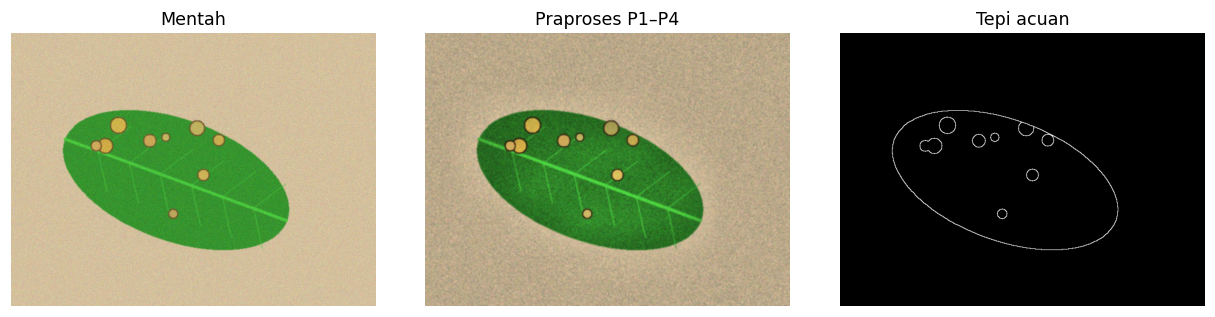

Selisih maksimum Gx dan Gy terhadap OpenCV = [0.0, 0.0]
Magnitudo maksimum = 610.6


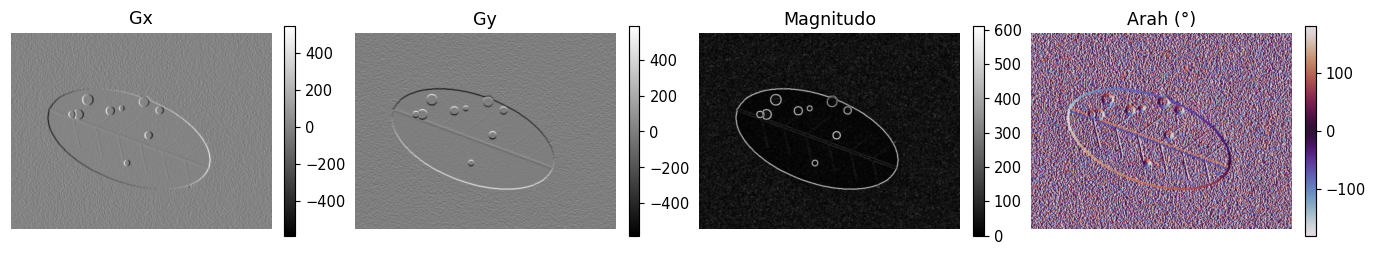

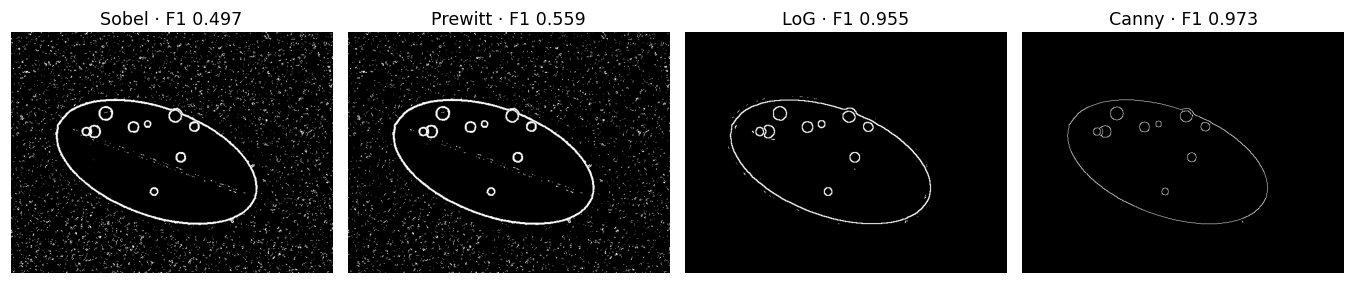

In [2]:
img, pra, md, mb = contoh["teh_041.png"]
acuan = cv2.bitwise_or(tepi_acuan(md), tepi_acuan(mb))
tampil([img, pra, acuan], ["Mentah", "Praproses P1–P4", "Tepi acuan"], ukuran=(12, 3))
simpan_gambar("p5_citra_dan_acuan.png")

g = pra[:, :, 2].astype(np.float32)
gx = cv2.filter2D(g, cv2.CV_32F, SOBEL_X)
gy = cv2.filter2D(g, cv2.CV_32F, SOBEL_X.T)
mag = np.hypot(gx, gy)
arah = np.degrees(np.arctan2(gy, gx))
selisih = [float(np.abs(gx - cv2.Sobel(g, cv2.CV_32F, 1, 0, ksize=3)).max()),
           float(np.abs(gy - cv2.Sobel(g, cv2.CV_32F, 0, 1, ksize=3)).max())]
print(f"Selisih maksimum Gx dan Gy terhadap OpenCV = {selisih}")
print(f"Magnitudo maksimum = {mag.max():.1f}")
assert max(selisih) == 0
fig, axes = plt.subplots(1, 4, figsize=(13, 3.2), layout="constrained")
for ax, im, judul, cmap in zip(axes, [gx, gy, mag, arah], ["Gx", "Gy", "Magnitudo", "Arah (°)"],
                               ["gray", "gray", "gray", "twilight"]):
    fig.colorbar(ax.imshow(im, cmap=cmap), ax=ax, shrink=.64)
    ax.set_title(judul)
    ax.axis("off")
simpan_gambar("p5_gradien.png")

deteksi = {nama: f(pra[:, :, 2]) for nama, f in metode.items()}
tampil(list(deteksi.values()), [f"{n} · F1 {skor_tepi(e, acuan)[2]:.3f}" for n, e in deteksi.items()],
       ukuran=(13, 3))
simpan_gambar("p5_operator.png")

                              P      R     F1
sumber    kanal operator                     
mentah    Gray  Canny     0.762  0.753  0.757
                LoG       0.633  0.999  0.767
                Prewitt   0.800  0.973  0.870
                Sobel     0.760  0.979  0.845
          R     Canny     0.989  0.985  0.987
                LoG       0.921  0.998  0.953
                Prewitt   0.551  0.997  0.647
                Sobel     0.501  0.997  0.596
praproses Gray  Canny     0.684  0.949  0.789
                LoG       0.553  0.998  0.702
                Prewitt   0.553  0.998  0.696
                Sobel     0.521  0.998  0.665
          R     Canny     0.958  0.992  0.973
                LoG       0.847  0.999  0.906
                Prewitt   0.441  0.998  0.566
                Sobel     0.400  0.998  0.524

Tabel 6, F1 gabungan batas daun dan bercak
 sumber   mentah        praproses       
kanal      Gray      R      Gray      R
operator                               
Canny  

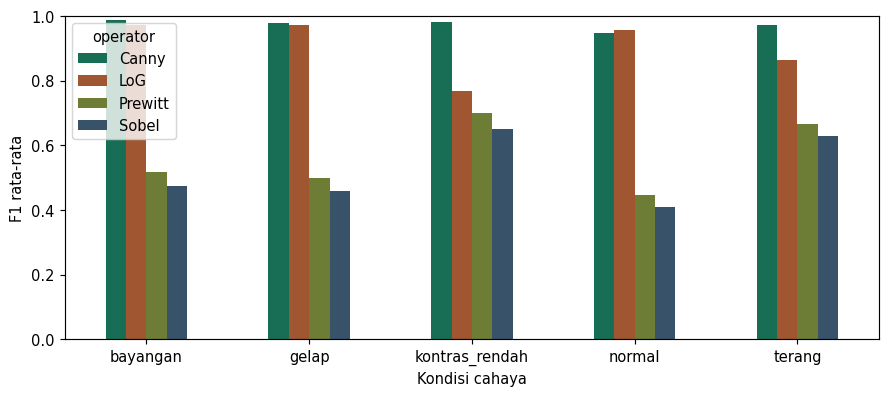

In [3]:
baris = []
for d, img, pra, md, mb in data:
    if d.kelas == "sehat":
        continue
    ad, ab = tepi_acuan(md), tepi_acuan(mb)
    ac = cv2.bitwise_or(ad, ab)
    for sumber, im in [("mentah", img), ("praproses", pra)]:
        for kanal, g in kanal_gray_r(im):
            for nama, f in metode.items():
                e = f(g)
                baris.append([d.nama_file, d.kelas, d.kondisi_cahaya, sumber, kanal, nama,
                              *skor_tepi(e, ac)])

tepi = pd.DataFrame(baris, columns=["citra", "kelas", "kondisi", "sumber", "kanal", "operator", "P", "R", "F1"])
assert len(tepi) == 40 * 2 * 2 * 4
tepi.to_csv(HASIL / "p5_tabel_tepi.csv", index=False)
ringkas = tepi.groupby(["sumber", "kanal", "operator"])[["P", "R", "F1"]].mean()
print(ringkas.round(3))
tabel6 = tepi.pivot_table(index="operator", columns=["sumber", "kanal"], values="F1")
print("\nTabel 6, F1 gabungan batas daun dan bercak\n", tabel6.round(3))
f1_cahaya = tepi.query("sumber == 'praproses' and kanal == 'R'").pivot_table(
    index="kondisi", columns="operator", values="F1")
f1_cahaya.plot.bar(figsize=(10, 4), rot=0, ylim=(0, 1), ylabel="F1 rata-rata",
                   xlabel="Kondisi cahaya", color=["#176e55", "#a05631", "#6d7d35", "#38526a"])
simpan_gambar("p5_f1_kondisi.png")

## 2. Canny

Bandingkan F1 batas gabungan dengan recall bercak untuk menjaga agar batas daun yang jauh lebih panjang tidak menutupi hilangnya bercak kecil.

Tabel 7
                    P      R     F1  berat  ringan
sigma ambang                                     
0     100/200  0.486  0.996  0.582  0.986   0.975
      30/90    0.021  0.998  0.040  0.992   0.986
      50/150   0.145  0.996  0.204  0.988   0.981
1     100/200  0.979  0.995  0.987  0.984   0.954
      30/90    0.245  0.996  0.326  0.988   0.961
      50/150   0.854  0.995  0.903  0.986   0.957
2     100/200  0.793  0.788  0.791  0.759   0.689
      30/90    0.958  0.992  0.973  0.967   0.942
      50/150   0.986  0.982  0.984  0.930   0.882

F1 metode otomatis dan pembanding
 kondisi            bayangan  gelap  kontras_rendah  normal  terang
kanal ambang                                                      
Gray  median          0.456  0.501           0.830   0.693   0.842
      q90             0.076  0.082           0.074   0.080   0.085
      q95             0.344  0.444           0.335   0.468   0.476
      q98             0.791  0.811           0.812   0.766   0.778
   

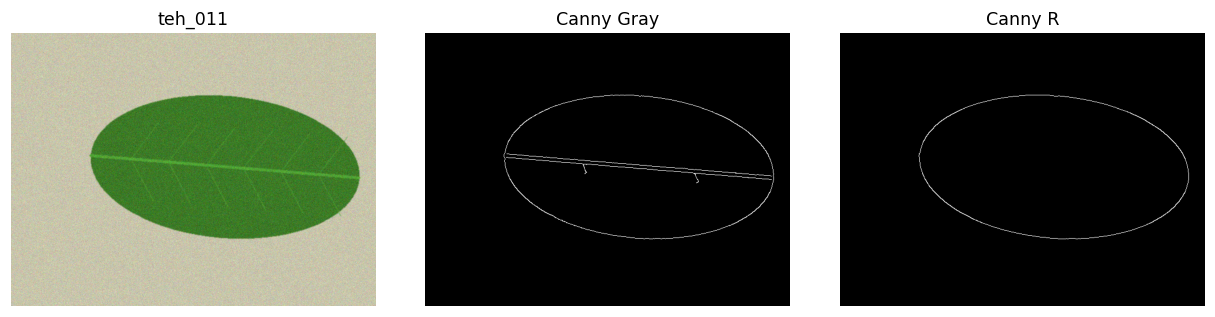

In [4]:
uji, otomatis, sehat, banding_gradien = [], [], [], []
for d, img, pra, md, mb in data:
    ad, ab = tepi_acuan(md), tepi_acuan(mb)
    ac = cv2.bitwise_or(ad, ab)
    if d.kelas == "sehat":
        dalam = cv2.erode(md, np.ones((7, 7), np.uint8)) > 0
        for kanal, g in kanal_gray_r(pra):
            e = tepi_canny(g)
            sehat.append([d.nama_file, d.kondisi_cahaya, kanal, int(np.count_nonzero((e > 0) & dalam))])
        continue

    for sigma in (0, 1, 2):
        for lo, hi in [(30, 90), (50, 150), (100, 200)]:
            e = tepi_canny(pra[:, :, 2], lo, hi, sigma)
            uji.append([d.nama_file, d.kelas, d.kondisi_cahaya, sigma, f"{lo}/{hi}",
                        *skor_tepi(e, ac), skor_tepi(e, ab)[1]])

    for kanal, g in kanal_gray_r(pra):
        prediksi = {"median": canny_otomatis(g), "tetap 30/90": tepi_canny(g)}
        for q in (90, 95, 98):
            prediksi[f"q{q}"] = canny_persentil(g, q)
        median = float(np.median(g))
        for aturan, e in prediksi.items():
            otomatis.append([d.nama_file, d.kondisi_cahaya, kanal, aturan, *skor_tepi(e, ac), median])
        if d.kondisi_cahaya == "kontras_rendah":
            pita = cv2.dilate(ad, np.ones((3, 3), np.uint8)) > 0
            mag = gradien(cv2.GaussianBlur(g, (0, 0), 2.0))
            banding_gradien.append([d.nama_file, kanal, median, int(.67 * median),
                                     int(min(255, 1.33 * median)), np.median(mag[pita]),
                                     np.percentile(mag[pita], 95)])

canny = pd.DataFrame(uji, columns=["citra", "kelas", "kondisi", "sigma", "ambang", "P", "R", "F1", "R_bercak"])
auto = pd.DataFrame(otomatis, columns=["citra", "kondisi", "kanal", "ambang", "P", "R", "F1", "median"])
sehat = pd.DataFrame(sehat, columns=["citra", "kondisi", "kanal", "tepi_dalam"])
gr = pd.DataFrame(banding_gradien, columns=["citra", "kanal", "median", "ambang_bawah", "ambang_atas", "gradien_p50", "gradien_p95"])
assert len(canny) == 360 and len(auto) == 400 and len(sehat) == 40
for nama, df in [("canny", canny), ("canny_otomatis", auto), ("tepi_palsu", sehat), ("gradien_kontras_rendah", gr)]:
    df.to_csv(HASIL / f"p5_{nama}.csv", index=False)

tabel7 = canny.groupby(["sigma", "ambang"])[["P", "R", "F1"]].mean().join(
    canny.pivot_table(index=["sigma", "ambang"], columns="kelas", values="R_bercak"))
print("Tabel 7\n", tabel7.round(3))
print("\nF1 metode otomatis dan pembanding\n", auto.pivot_table(index=["kanal", "ambang"], columns="kondisi", values="F1").round(3))
print("\nMedian intensitas\n", auto.groupby(["kanal", "kondisi"]).median(numeric_only=True)["median"])
print("\nAmbang dan gradien sekitar batas daun, kondisi kontras rendah\n", gr.groupby("kanal").mean(numeric_only=True).round(2))
print("\nRata-rata tepi interior per daun sehat\n", sehat.pivot_table(index="kondisi", columns="kanal", values="tepi_dalam").round(1))
img, pra, md, mb = contoh["teh_011.png"]
tampil([img] + [tepi_canny(g) for _, g in kanal_gray_r(pra)], ["teh_011", "Canny Gray", "Canny R"], ukuran=(12, 3))
simpan_gambar("p5_tepi_sehat.png")

## Keputusan penggunaan tepi

Nilai F1 gabungan menilai respons terhadap batas daun dan bercak. Ukuran area tetap berasal dari mask wilayah. Lihat Tabel 8 dan pembahasannya di laporan untuk keputusan per kebutuhan.